In [697]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import numpy as np
import seaborn as sns
import matplotlib

In [698]:
df = pd.read_csv('data/final_data.csv')


print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (10754, 22)


,player,team,name,position,height,age,appearance,goals,assists,yellow cards,...,goals conceded,clean sheets,minutes played,days_injured,games_injured,award,current_value,highest_value,position_encoded,winger
0,/david-de-gea/profil/spieler/59377,Manchester United,David de Gea,Goalkeeper,189.0,32.0,104,0.000000,0.000000,0.009585,...,1.217252,0.335463,9390,42,5,13,15000000,70000000,1,0
1,/jack-butland/profil/spieler/128899,Manchester United,Jack Butland,Goalkeeper,196.0,30.0,15,0.000000,0.000000,0.069018,...,1.242331,0.207055,1304,510,58,1,1500000,22000000,1,0
2,/tom-heaton/profil/spieler/34130,Manchester United,Tom Heaton,Goalkeeper,188.0,37.0,4,0.000000,0.000000,0.000000,...,0.616438,0.924658,292,697,84,4,600000,6000000,1,0
3,/lisandro-martinez/profil/spieler/480762,Manchester United,Lisandro Martínez,Defender Centre-Back,175.0,25.0,82,0.028090,0.056180,0.224719,...,0.000000,0.000000,6408,175,22,9,50000000,50000000,2,0
4,/raphael-varane/profil/spieler/164770,Manchester United,Raphaël Varane,Defender Centre-Back,191.0,30.0,63,0.017889,0.017889,0.053667,...,0.000000,0.000000,5031,238,51,21,40000000,80000000,2,0


In [699]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10754 entries, 0 to 10753
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   player               10754 non-null  object 
 1   team                 10754 non-null  object 
 2   name                 10754 non-null  object 
 3   position             10754 non-null  object 
 4   height               10754 non-null  float64
 5   age                  10754 non-null  float64
 6   appearance           10754 non-null  int64  
 7   goals                10754 non-null  float64
 8   assists              10754 non-null  float64
 9   yellow cards         10754 non-null  float64
 10  second yellow cards  10754 non-null  float64
 11  red cards            10754 non-null  float64
 12  goals conceded       10754 non-null  float64
 13  clean sheets         10754 non-null  float64
 14  minutes played       10754 non-null  int64  
 15  days_injured         10754 non-null 

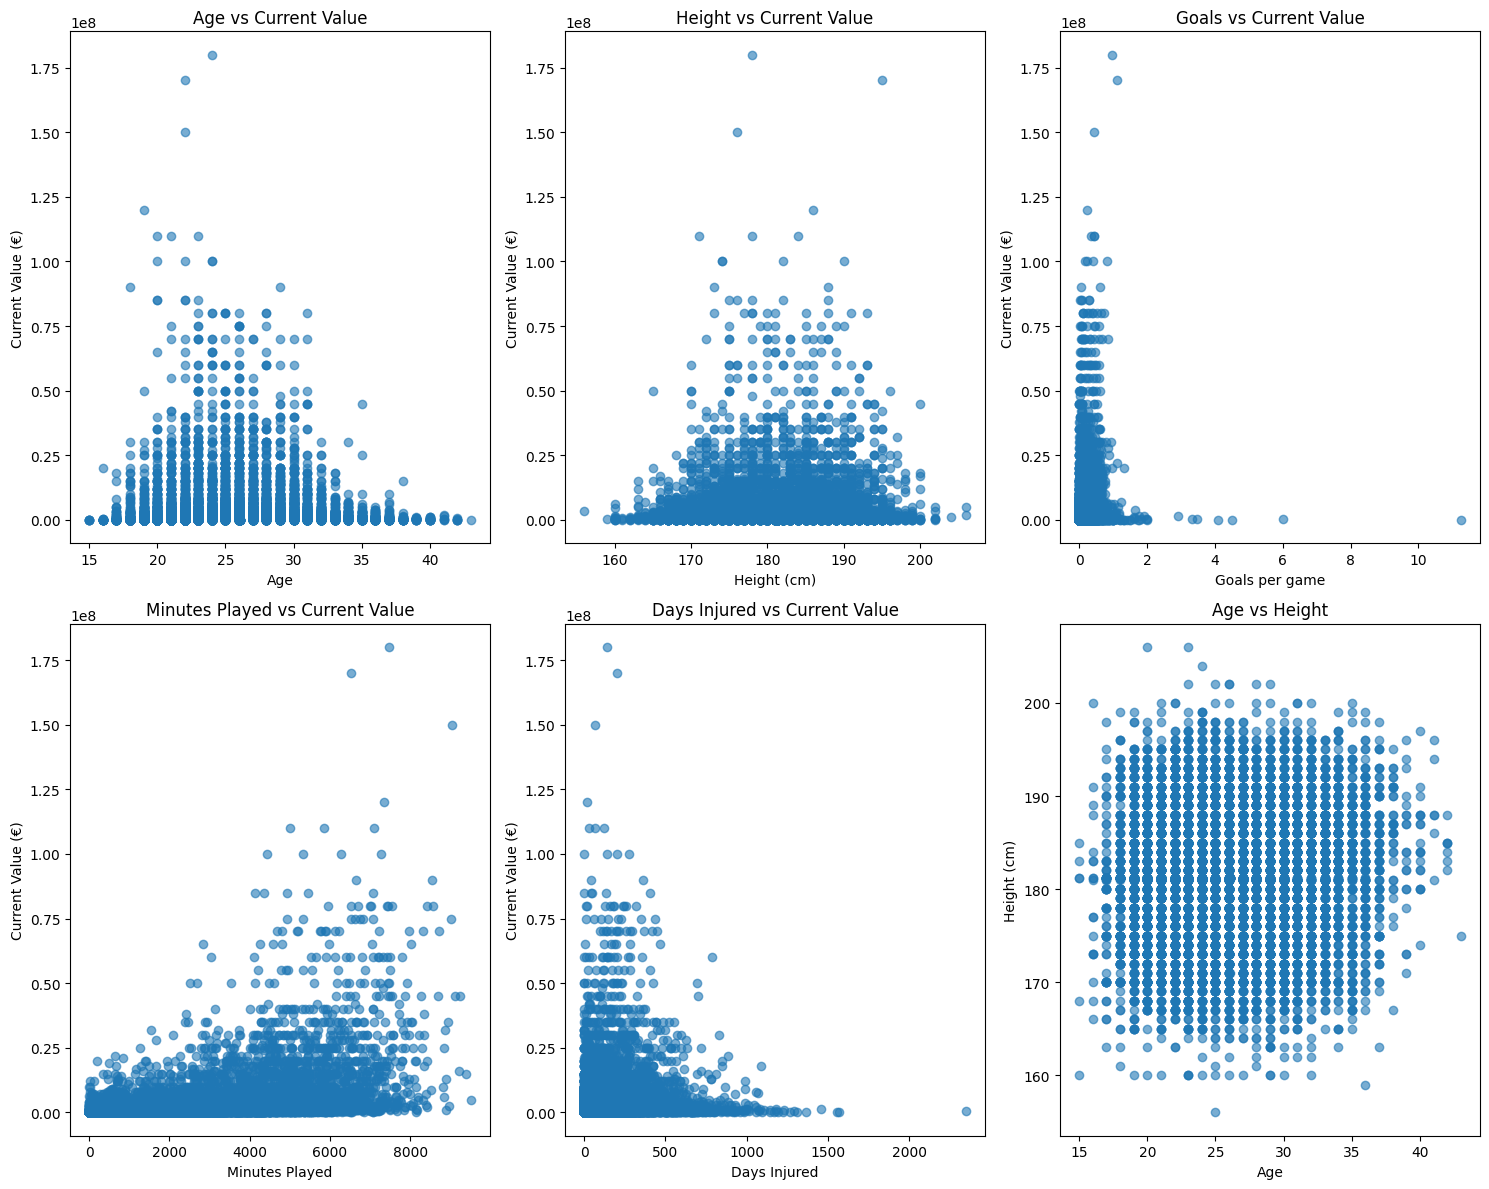

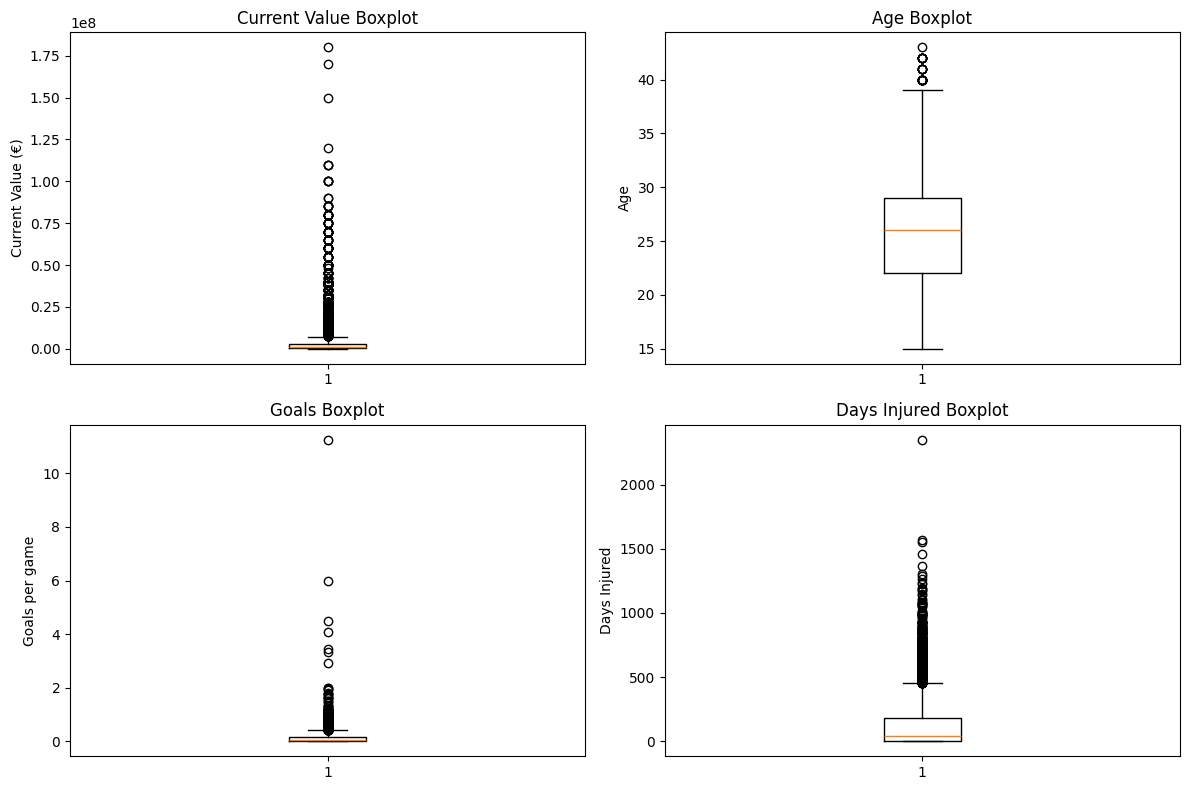

In [700]:
# Scatterplots för att hitta outliers
plt.figure(figsize=(15, 12))

# Age vs Current Value
plt.subplot(2, 3, 1)
plt.scatter(df['age'], df['current_value'], alpha=0.6)
plt.xlabel('Age')
plt.ylabel('Current Value (€)')
plt.title('Age vs Current Value')

# Height vs Current Value 
plt.subplot(2, 3, 2)
plt.scatter(df['height'], df['current_value'], alpha=0.6)
plt.xlabel('Height (cm)')
plt.ylabel('Current Value (€)')
plt.title('Height vs Current Value')

# Goals vs Current Value
plt.subplot(2, 3, 3)
plt.scatter(df['goals'], df['current_value'], alpha=0.6)
plt.xlabel('Goals per game')
plt.ylabel('Current Value (€)')
plt.title('Goals vs Current Value')

# Minutes played vs Current Value
plt.subplot(2, 3, 4)
plt.scatter(df['minutes played'], df['current_value'], alpha=0.6)
plt.xlabel('Minutes Played')
plt.ylabel('Current Value (€)')
plt.title('Minutes Played vs Current Value')

# Days injured vs Current Value
plt.subplot(2, 3, 5)
plt.scatter(df['days_injured'], df['current_value'], alpha=0.6)
plt.xlabel('Days Injured')
plt.ylabel('Current Value (€)')
plt.title('Days Injured vs Current Value')

# Age vs Height (för att se fysiska outliers)
plt.subplot(2, 3, 6)
plt.scatter(df['age'], df['height'], alpha=0.6)
plt.xlabel('Age')
plt.ylabel('Height (cm)')
plt.title('Age vs Height')

plt.tight_layout()
plt.show()

# Boxplot för att identifiera outliers i värden
plt.figure(figsize=(12, 8))

# Current Value boxplot
plt.subplot(2, 2, 1)
plt.boxplot(df['current_value'].dropna())
plt.ylabel('Current Value (€)')
plt.title('Current Value Boxplot')

# Age boxplot
plt.subplot(2, 2, 2)
plt.boxplot(df['age'].dropna())
plt.ylabel('Age')
plt.title('Age Boxplot')

# Goals boxplot
plt.subplot(2, 2, 3)
plt.boxplot(df['goals'].dropna())
plt.ylabel('Goals per game')
plt.title('Goals Boxplot')

# Days injured boxplot
plt.subplot(2, 2, 4)
plt.boxplot(df['days_injured'].dropna())
plt.ylabel('Days Injured')
plt.title('Days Injured Boxplot')

plt.tight_layout()
plt.show()

In [701]:
# Top 10 spelare med högst highest_value
top_10_highest = df.nlargest(10, 'highest_value')[['name', 'team', 'position', 'age', 'current_value', 'highest_value']]
print("Top 10 spelare med högst highest_value:")
print("=" * 50)
for i, (_, player) in enumerate(top_10_highest.iterrows(), 1):
    print(f"{i:2}. {player['name']:20} ({player['team']:15}) - {player['highest_value']:>12,}€")
    print(f"    Position: {player['position']:20} Ålder: {player['age']} Current: {player['current_value']:>12,}€")
    print()

Top 10 spelare med högst highest_value:
 1. Kylian Mbappé        (Paris Saint-Germain) -  200,000,000€
    Position: Attack Centre-Forward Ålder: 24.0 Current:  180,000,000€

 2. Neymar               (Paris Saint-Germain) -  180,000,000€
    Position: Attack-LeftWinger    Ålder: 31.0 Current:   70,000,000€

 3. Lionel Messi         (Paris Saint-Germain) -  180,000,000€
    Position: Attack-RightWinger   Ålder: 35.0 Current:   45,000,000€

 4. Erling Haaland       (Manchester City) -  170,000,000€
    Position: Attack Centre-Forward Ålder: 22.0 Current:  170,000,000€

 5. Raheem Sterling      (Chelsea FC     ) -  160,000,000€
    Position: Attack-LeftWinger    Ålder: 28.0 Current:   60,000,000€

 6. Philippe Coutinho    (Aston Villa    ) -  150,000,000€
    Position: Attack-LeftWinger    Ålder: 30.0 Current:   14,000,000€

 7. Mohamed Salah        (Liverpool FC   ) -  150,000,000€
    Position: Attack-RightWinger   Ålder: 30.0 Current:   70,000,000€

 8. Kevin De Bruyne      (Manchester

Jag börjar med att tvätta datan

In [702]:
print("Missing values per kolumn:")
print(df.isnull().sum())


Missing values per kolumn:
player                 0
team                   0
name                   0
position               0
height                 0
age                    0
appearance             0
goals                  0
assists                0
yellow cards           0
second yellow cards    0
red cards              0
goals conceded         0
clean sheets           0
minutes played         0
days_injured           0
games_injured          0
award                  0
current_value          0
highest_value          0
position_encoded       0
winger                 0
dtype: int64


jag har inga missing values

In [703]:
# Först kolla alla unika lag för att identifiera ligorna
print("Antal unika lag:", df['team'].nunique())
print("\nAlla lag:")
all_teams = sorted(df['team'].unique())
for team in all_teams:
    print(team)

Antal unika lag: 374

Alla lag:
1.FC Köln
1.FC Union Berlin
1.FSV Mainz 05
AA Argentinos Juniors
AC Ajaccio
AC Milan
AC Monza
ACF Fiorentina
AFC Bournemouth
AJ Auxerre
AS Monaco
AS Roma
AZ Alkmaar
Abha Club
Adana Demirspor
Adelaide United
Ajax Amsterdam
Akhmat Grozny
Al-Adalah FC
Al-Batin FC
Al-Fateh SC
Al-Fayha FC
Al-Hilal Saudi FC
Al-Ittihad Club (Jeddah)
Al-Khaleej
Al-Nassr FC
Al-Raed SFC
Al-Shabab Club (Riyadh)
Al-Taawoun FC
Al-Tai
Al-Wehda FC
Alanyaspor
Albirex Niigata
AmaZulu FC
América Futebol Clube (MG)
Angers SCO
Antalyaspor
Arsenal FC
Arsenal Fútbol Club
Aston Villa
Atalanta BC
Athletic Bilbao
Atlanta United FC
Atlas Guadalajara
Atlético de Madrid
Atlético de San Luis
Austin FC
Austria Vienna
Avispa Fukuoka
Basaksehir FK
Bayer 04 Leverkusen
Bayern Munich
Besiktas JK
Birmingham City
Blackburn Rovers
Blackpool FC
Boavista FC
Bologna FC 1909
Borussia Dortmund
Borussia Mönchengladbach
Botafogo de Futebol e Regatas
Brentford FC
Brighton &amp; Hove Albion
Brisbane Roar
Bristol City

In [704]:
# Definiera lag från ligorna som ska filtreras bort baserat på output ovan:

# Amerikanska ligor
brazilian_teams = [
    'CR Flamengo', 'Sociedade Esportiva Palmeiras', 'Santos FC', 'Sport Club Corinthians Paulista',
    'Clube Atlético Mineiro', 'Sport Club Internacional', 'Grêmio Foot-Ball Porto Alegrense',
    'Fluminense Football Club', 'Botafogo de Futebol e Regatas', 'Clube de Regatas Vasco da Gama',
    'Cruzeiro Esporte Clube', 'América Futebol Clube (MG)', 'Club Athletico Paranaense',
    'Coritiba Foot Ball Club', 'Fortaleza Esporte Clube', 'Esporte Clube Bahia',
    'Cuiabá Esporte Clube (MT)', 'Goiás Esporte Clube', 'Red Bull Bragantino'
]

mls_teams = [
    'Atlanta United FC', 'Austin FC', 'Charlotte FC', 'Chicago Fire FC', 'Colorado Rapids',
    'Columbus Crew', 'D.C. United', 'FC Cincinnati', 'FC Dallas', 'Houston Dynamo FC',
    'Inter Miami CF', 'Los Angeles FC', 'Los Angeles Galaxy', 'Minnesota United FC',
    'Nashville SC', 'New England Revolution', 'New York City FC', 'New York Red Bulls',
    'Orlando City SC', 'Philadelphia Union', 'Portland Timbers', 'Real Salt Lake City',
    'San Jose Earthquakes', 'Seattle Sounders FC', 'Sporting Kansas City', 'Toronto FC',
    'Vancouver Whitecaps FC', 'CF Montréal'
]

argentine_teams = [
    'CA Boca Juniors', 'CA River Plate', 'Racing Club', 'CA Independiente',
    'CA San Lorenzo de Almagro', 'Club Estudiantes de La Plata', 'Club de Gimnasia y Esgrima La Plata',
    'CA Newell\'s Old Boys', 'CA Rosario Central', 'CA Banfield', 'Club Atlético Lanús',
    'Defensa y Justicia', 'Club Atlético Talleres', 'CA Vélez Sarsfield', 'CA Huracán',
    'AA Argentinos Juniors', 'Club Atlético Tigre', 'Club Atlético Platense',
    'CA Central Córdoba (SdE)', 'CA Barracas Central', 'CA Sarmiento (Junin)',
    'CD Godoy Cruz Antonio Tomba', 'Club Atlético Belgrano', 'Club Atlético Tucumán',
    'Club Atlético Unión', 'CA Colon', 'Instituto AC Córdoba'
]

mexican_teams = [
    'CF América', 'Deportivo Guadalajara', 'CD Cruz Azul', 'Universidad Nacional',
    'Club León FC', 'CF Monterrey', 'Santos Laguna', 'Deportivo Toluca',
    'Atlas Guadalajara', 'CF Pachuca', 'Club Necaxa', 'Puebla FC',
    'Querétaro FC', 'Club Tijuana', 'FC Juárez', 'Mazatlán FC', 'Atlético de San Luis'
]

# Afrikanska ligor
south_african_teams = [
    'Kaizer Chiefs', 'Orlando Pirates', 'Mamelodi Sundowns FC', 'SuperSport United FC',
    'Cape Town City FC', 'AmaZulu FC', 'Chippa United', 'Maritzburg United FC',
    'Marumo Gallants FC', 'Lamontville Golden Arrows', 'Richards Bay FC',
    'Royal AM FC', 'Sekhukhune United FC', 'TS Galaxy FC', 'University of Pretoria FC'
]

# Asiatiska ligor
japanese_teams = [
    'Urawa Red Diamonds', 'Kashima Antlers', 'Gamba Osaka', 'Yokohama F. Marinos',
    'Kawasaki Frontale', 'Cerezo Osaka', 'Vissel Kobe', 'FC Tokyo', 'Nagoya Grampus',
    'Sanfrecce Hiroshima', 'Kashiwa Reysol', 'Sagan Tosu', 'Avispa Fukuoka',
    'Shonan Bellmare', 'Albirex Niigata', 'Hokkaido Consadole Sapporo', 'Kyoto Sanga',
    'Tokushima Vortis', 'Ventforet Kofu'
]

saudi_teams = [
    'Al-Hilal Saudi FC', 'Al-Nassr FC', 'Al-Ahli Saudi FC', 'Al-Ittihad Club (Jeddah)',
    'Al-Shabab Club (Riyadh)', 'Al-Fateh SC', 'Al-Taawoun FC', 'Ettifaq FC',
    'Al-Raed SFC', 'Al-Fayha FC', 'Al-Wehda FC', 'Al-Batin FC', 'Al-Adalah FC',
    'Al-Khaleej', 'Al-Tai', 'Abha Club', 'Damac FC'
]

korean_teams = [
    'Jeonbuk Hyundai Motors', 'Ulsan Hyundai', 'Pohang Steelers', 'Suwon Samsung Bluewings',
    'FC Seoul', 'Daegu FC', 'Incheon United', 'Jeju United', 'Gangwon FC',
    'Gwangju FC', 'Daejeon Hana Citizen', 'Seongnam FC', 'Suwon FC'
]

australian_teams = [
    'Sydney FC', 'Melbourne City FC', 'Melbourne Victory', 'Western Sydney Wanderers FC',
    'Adelaide United', 'Brisbane Roar', 'Perth Glory', 'Wellington Phoenix',
    'Central Coast Mariners', 'Newcastle United Jets', 'Western United FC',
    'Macarthur FC'
]

# Kombinera alla lag som ska filtreras bort
teams_to_remove = (
    brazilian_teams + mls_teams + argentine_teams + mexican_teams +
    south_african_teams + japanese_teams + saudi_teams + korean_teams + australian_teams
)

original_size = len(df)
print(f"Antal rader innan filtrering: {original_size}")
print(f"Antal lag att filtrera bort: {len(teams_to_remove)}")

# Kontrollera vilka lag som faktiskt finns innan filtrering
actually_removed = set(df['team'].unique()) & set(teams_to_remove)
print(f"\nAktuella lag som kommer filtreras bort ({len(actually_removed)}):")  
for team in sorted(actually_removed):
    count = len(df[df['team'] == team])
    print(f"  {team}: {count} spelare")

# Filtrera bort dessa lag direkt från original df
df = df[~df['team'].isin(teams_to_remove)]

print(f"\nAntal rader efter filtrering: {len(df)}")
print(f"Antal borttagna rader: {original_size - len(df)}")
print(f"Procent kvar: {len(df)/original_size*100:.1f}%")

Antal rader innan filtrering: 10754
Antal lag att filtrera bort: 167

Aktuella lag som kommer filtreras bort (159):
  AA Argentinos Juniors: 30 spelare
  Abha Club: 36 spelare
  Adelaide United: 30 spelare
  Al-Adalah FC: 33 spelare
  Al-Batin FC: 41 spelare
  Al-Fateh SC: 25 spelare
  Al-Fayha FC: 27 spelare
  Al-Hilal Saudi FC: 32 spelare
  Al-Ittihad Club (Jeddah): 31 spelare
  Al-Khaleej: 30 spelare
  Al-Nassr FC: 29 spelare
  Al-Raed SFC: 27 spelare
  Al-Shabab Club (Riyadh): 35 spelare
  Al-Taawoun FC: 37 spelare
  Al-Tai: 33 spelare
  Al-Wehda FC: 35 spelare
  Albirex Niigata: 32 spelare
  AmaZulu FC: 32 spelare
  América Futebol Clube (MG): 34 spelare
  Atlanta United FC: 28 spelare
  Atlas Guadalajara: 26 spelare
  Atlético de San Luis: 26 spelare
  Austin FC: 29 spelare
  Avispa Fukuoka: 32 spelare
  Botafogo de Futebol e Regatas: 38 spelare
  Brisbane Roar: 30 spelare
  CA Banfield: 29 spelare
  CA Barracas Central: 29 spelare
  CA Boca Juniors: 33 spelare
  CA Central Córdo

Jag väljer att fokusera enbart på den europeiska marknaden då det är där fotboll är som störst och det är där det finns mest pengar.(fotbollens hjärta) Antalet spelare som inte går för några seriösa summor är för många de andra ligorna inkluderade. Desutom så generellt om en spelare har potential och är seriös så finner den sig någonstans i dessa ligorna. Oavsett härkomst

In [705]:
df.dtypes

player                  object
team                    object
name                    object
position                object
height                 float64
age                    float64
appearance               int64
goals                  float64
assists                float64
yellow cards           float64
second yellow cards    float64
red cards              float64
goals conceded         float64
clean sheets           float64
minutes played           int64
days_injured             int64
games_injured            int64
award                    int64
current_value            int64
highest_value            int64
position_encoded         int64
winger                   int64
dtype: object

droppa kolumner som jag inte behöver

In [706]:
df = df.drop(columns=['name'])

In [707]:
df = df.drop(columns=['player'])


In [708]:
df.dtypes

team                    object
position                object
height                 float64
age                    float64
appearance               int64
goals                  float64
assists                float64
yellow cards           float64
second yellow cards    float64
red cards              float64
goals conceded         float64
clean sheets           float64
minutes played           int64
days_injured             int64
games_injured            int64
award                    int64
current_value            int64
highest_value            int64
position_encoded         int64
winger                   int64
dtype: object

In [709]:

print("Position kolumn:")
print(f"Antal unika värden: {df['position'].nunique()}")

print(f"Värderäkning:\n{df['position'].value_counts()}")

print("\n" + "="*50 + "\n")


print("Position_encoded kolumn:")
print(f"Antal unika värden: {df['position_encoded'].nunique()}")
print(f"Unika värden: {df['position_encoded'].unique()}")
print(f"Värderäkning:\n{df['position_encoded'].value_counts()}")

Position kolumn:
Antal unika värden: 15
Värderäkning:
position
Defender Centre-Back          1019
Attack Centre-Forward          744
midfield-CentralMidfield       705
Goalkeeper                     693
Defender Right-Back            496
midfield-DefensiveMidfield     468
Defender Left-Back             449
midfield-AttackingMidfield     409
Attack-RightWinger             386
Attack-LeftWinger              374
midfield-RightMidfield          45
midfield-LeftMidfield           39
Attack-SecondStriker            28
midfield                         6
Defender                         2
Name: count, dtype: int64


Position_encoded kolumn:
Antal unika värden: 4
Unika värden: [1 2 3 4]
Värderäkning:
position_encoded
2    1966
3    1672
4    1532
1     693
Name: count, dtype: int64


här ser jag att de finns 15 olika positioner men bara 4st encoded position. vilket gör att modellen enbart skulle göra skillnad på målvakt, försvarare, mittfält och anfallare. för att göra den mer precis vill jag skapa en position_encoded för varje exakt position.

alternativt att jag behåller de 4 som finns och tar bort position kolumnen. 
1 = målvakt 
2 = försvarare 
3 = mittfält
4 = anfallare

In [710]:
df = df.drop(columns=['position'])

In [711]:
df['team'].nunique()

215

In [712]:
df = pd.get_dummies(df, columns=['team'], drop_first=True)

anledningen till att jag behåller team och one-hot encodear den är att jag vill se om team påverkar value. t.ex om en spelare i lag x har exakt samma stats som spelare i lag y. får de olika value? min bedömning av verkligheten är att spelare i topplag är oftast värderade högre. trots att de är svårare att uppnå samma stats i ett sämre lag eftersom de generellt har sämre lagspelare. Det skiljer sig lite från de olika positionerna. en anfallare i ett sämre lag har kanske färre mål men en försvarare har fler defensiva aktioner per match som man använder mer för att värdera en försvarare.

In [713]:
df.head()

,height,age,appearance,goals,assists,yellow cards,second yellow cards,red cards,goals conceded,clean sheets,...,team_Watford FC,team_West Bromwich Albion,team_West Ham United,team_Western Sydney Wanderers,team_Wigan Athletic,team_Wolfsberger AC,team_Wolverhampton Wanderers,team_Yokohama FC,team_Zenit St. Petersburg,team_Ümraniyespor
0,189.0,32.0,104,0.000000,0.000000,0.009585,0.0,0.0,1.217252,0.335463,...,False,False,False,False,False,False,False,False,False,False
1,196.0,30.0,15,0.000000,0.000000,0.069018,0.0,0.0,1.242331,0.207055,...,False,False,False,False,False,False,False,False,False,False
2,188.0,37.0,4,0.000000,0.000000,0.000000,0.0,0.0,0.616438,0.924658,...,False,False,False,False,False,False,False,False,False,False
3,175.0,25.0,82,0.028090,0.056180,0.224719,0.0,0.0,0.000000,0.000000,...,False,False,False,False,False,False,False,False,False,False
4,191.0,30.0,63,0.017889,0.017889,0.053667,0.0,0.0,0.000000,0.000000,...,False,False,False,False,False,False,False,False,False,False


In [714]:
correlation = df.corr()
target_correlation = correlation['current_value'].sort_values(ascending=False)
print("Korrelation med current_value:")
print(target_correlation)

Korrelation med current_value:
current_value        1.000000
highest_value        0.834766
appearance           0.412084
minutes played       0.403675
award                0.329245
                       ...   
team_TSV Hartberg   -0.035174
team_Yokohama FC    -0.036786
team_Swallows FC    -0.039347
age                 -0.062211
goals conceded      -0.098397
Name: current_value, Length: 232, dtype: float64


först tränar jag en modell och kollar score. därefter skapar jag lite ratio features o tränar igen för att se om score blir bättre

ta bort highest value?

Få sämre prediktionsförmåga eftersom highest_value har stark korrelation med current_value
Men gör modellen mer användbar för riktiga prediktioner där jag inte känner till det högsta värdet ännu (yngre up and coming spelare)
Det är en klassisk trade-off mellan träffsäkerhet och praktisk användbarhet.

In [715]:
df_UHV = df.copy()

In [716]:
df_UHV = df_UHV.drop(columns=['highest_value'])

In [717]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

# Separera features och target
X = df_UHV.drop(columns=['current_value'])
y = df_UHV['current_value']

# Dela upp datan i 80% träning och 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Träna modellen på träningsdatan
model = LinearRegression()
model.fit(X_train, y_train)

print(f"Modellen är tränad på {len(X_train)} observationer (träningsdata)")
print(f"Testdata innehåller {len(X_test)} observationer")

# Gör prediktioner på testdatan
y_pred = model.predict(X_test)

# Beräkna R² score på testdatan
r2 = r2_score(y_test, y_pred)
print(f"R² score på testdata: {r2:.4f}")

Modellen är tränad på 4690 observationer (träningsdata)
Testdata innehåller 1173 observationer
R² score på testdata: 0.4620


In [718]:
# Träna modellen på all data (träning + test)
model_all = LinearRegression()
model_all.fit(X, y)

print(f"Modellen är tränad på {len(X)} observationer (all data)")

# Gör prediktioner och beräkna R2 score på all data
y_pred_all = model_all.predict(X)
r2_all = r2_score(y, y_pred_all)
print(f"R² score på all data: {r2_all:.4f}")

Modellen är tränad på 5863 observationer (all data)
R² score på all data: 0.5577


In [719]:
from sklearn.ensemble import RandomForestRegressor

# Separera features och target (samma som tidigare)
X = df_UHV.drop(columns=['current_value'])
y = df_UHV['current_value']

# Dela upp datan i 80% träning och 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Träna Random Forest modellen på träningsdatan
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

print(f"Random Forest modellen är tränad på {len(X_train)} observationer (träningsdata)")
print(f"Testdata innehåller {len(X_test)} observationer")

# Gör prediktioner på testdatan
y_pred_rf = rf_model.predict(X_test)

# Beräkna R² score på testdatan
r2_rf = r2_score(y_test, y_pred_rf)
print(f"Random Forest R² score på testdata: {r2_rf:.4f}")

Random Forest modellen är tränad på 4690 observationer (träningsdata)
Testdata innehåller 1173 observationer
Random Forest R² score på testdata: 0.5925


In [720]:
# Spara modellen med team features
import pickle

# Träna modell på all data för bästa prestanda
rf_model_final = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model_final.fit(X, y)

# Beräkna R² score på all data
y_pred_final = rf_model_final.predict(X)
r2_final = r2_score(y, y_pred_final)

print(f"Final modell R² score: {r2_final:.4f}")
print(f"Antal features: {X.shape[1]}")

# Spara modellen med features och score
model_data = {
    'model': rf_model_final,
    'features': list(X.columns),
    'r2_score': r2_final
}

with open('football_value_model.pkl', 'wb') as f:
    pickle.dump(model_data, f)

print(f"\nModell sparad som 'football_value_model.pkl'")
print(f"Inkluderar {len([f for f in X.columns if f.startswith('team_')])} team features")

Final modell R² score: 0.9425
Antal features: 230

Modell sparad som 'football_value_model.pkl'
Inkluderar 214 team features


In [721]:
# Träna Random Forest modellen på all data (träning + test)
rf_model_all = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model_all.fit(X, y)

print(f"Random Forest modellen är tränad på {len(X)} observationer (all data)")

# Gör prediktioner och beräkna R2 score på all data
y_pred_all_rf = rf_model_all.predict(X)
r2_all_rf = r2_score(y, y_pred_all_rf)
print(f"Random Forest R² score på all data: {r2_all_rf:.4f}")

Random Forest modellen är tränad på 5863 observationer (all data)
Random Forest R² score på all data: 0.9425


Nu kommer jag skapa lite ratio features för att se om jag kan få upp R2 score på Random forest 

In [722]:
df = df.drop(columns=['highest_value'])

In [723]:

df['goals_per_game'] = df['goals'] / df['appearance']
df['assists_per_game'] = df['assists'] / df['appearance']
df['minutes_per_game'] = df['minutes played'] / df['appearance']
df['clean_sheets_per_game'] = df['clean sheets'] / df['appearance']
df['injury_rate'] = df['days_injured'] / df['appearance']


ratio_features = ['goals_per_game', 'assists_per_game', 'minutes_per_game', 'clean_sheets_per_game', 'injury_rate']
print("Ratio features har skapats:")
print(df[ratio_features].head(10))



Ratio features har skapats:
   goals_per_game  assists_per_game  minutes_per_game  clean_sheets_per_game  \
0        0.000000          0.000000         90.288462               0.003226   
1        0.000000          0.000000         86.933333               0.013804   
2        0.000000          0.000000         73.000000               0.231164   
3        0.000343          0.000685         78.146341               0.000000   
4        0.000284          0.000284         79.857143               0.000000   
5        0.000556          0.000000         70.029412               0.000000   
6        0.000000          0.000470         78.157143               0.000000   
7        0.000000          0.000000         52.000000               0.000000   
8        0.000000          0.000000         81.117647               0.000000   
9        0.000208          0.002285         79.108108               0.000000   

   injury_rate  
0     0.403846  
1    34.000000  
2   174.250000  
3     2.134146  
4     

In [724]:
with pd.option_context('display.max_columns', None):
    display(df.head())

,height,age,appearance,goals,assists,yellow cards,second yellow cards,red cards,goals conceded,clean sheets,minutes played,days_injured,games_injured,award,current_value,position_encoded,winger,team_1.FC Union Berlin,team_1.FSV Mainz 05,team_AC Ajaccio,team_AC Milan,team_AC Monza,team_ACF Fiorentina,team_AFC Bournemouth,team_AJ Auxerre,team_AS Monaco,team_AS Roma,team_AZ Alkmaar,team_Adana Demirspor,team_Ajax Amsterdam,team_Akhmat Grozny,team_Alanyaspor,team_Angers SCO,team_Antalyaspor,team_Arsenal FC,team_Arsenal Fútbol Club,team_Aston Villa,team_Atalanta BC,team_Athletic Bilbao,team_Atlético de Madrid,team_Austria Vienna,team_Basaksehir FK,team_Bayer 04 Leverkusen,team_Bayern Munich,team_Besiktas JK,team_Birmingham City,team_Blackburn Rovers,team_Blackpool FC,team_Boavista FC,team_Bologna FC 1909,team_Borussia Dortmund,team_Borussia Mönchengladbach,team_Brentford FC,team_Brighton &amp; Hove Albion,team_Bristol City,team_Burnley FC,team_CA Osasuna,team_CD Santa Clara,team_CS Marítimo,team_CSKA Moscow,team_Cardiff City,team_Casa Pia AC,team_Celta de Vigo,team_Chelsea FC,team_Clermont Foot 63,team_Coventry City,team_Crystal Palace,team_Cádiz CF,team_Dynamo Moscow,team_ESTAC Troyes,team_Eintracht Frankfurt,team_Elche CF,team_Everton FC,team_Excelsior Rotterdam,team_FC Arouca,team_FC Augsburg,team_FC Barcelona,team_FC Emmen,team_FC Empoli,team_FC Famalicão,team_FC Groningen,team_FC Lorient,team_FC Nantes,team_FC Pari Nizhniy Novgorod,team_FC Paços de Ferreira,team_FC Porto,team_FC Schalke 04,team_FC Sochi,team_FC Toulouse,team_FC Utrecht,team_FC Vizela,team_FC Volendam,team_FK Khimki,team_FK Krasnodar,team_FK Orenburg,team_FK Rostov,team_Fakel Voronezh,team_Fatih Karagümrük,team_Fenerbahce,team_Feyenoord Rotterdam,team_Fortuna Sittard,team_Fulham FC,team_GD Chaves,team_GD Estoril Praia,team_Galatasaray,team_Gaziantep FK,team_Getafe CF,team_Gil Vicente FC,team_Giresunspor,team_Girona FC,team_Go Ahead Eagles,team_Hatayspor,team_Hellas Verona,team_Hertha BSC,team_Huddersfield Town,team_Hull City,team_Inter Milan,team_Istanbulspor,team_Juventus FC,team_Kasimpasa,team_Kayserispor,team_Konyaspor,team_Krylya Sovetov Samara,team_LASK,team_LOSC Lille,team_Leeds United,team_Leicester City,team_Liverpool FC,team_Lokomotiv Moscow,team_Luton Town,team_MKE Ankaragücü,team_Manchester City,team_Manchester United,team_Middlesbrough FC,team_Millwall FC,team_Montpellier HSC,team_NEC Nijmegen,team_Newcastle United,team_Norwich City,team_Nottingham Forest,team_OGC Nice,team_Olympique Lyon,team_Olympique Marseille,team_PSV Eindhoven,team_Paris Saint-Germain,team_Portimonense SC,team_Preston North End,team_Queens Park Rangers,team_RB Leipzig,team_RC Lens,team_RC Strasbourg Alsace,team_RCD Espanyol Barcelona,team_RCD Mallorca,team_RKC Waalwijk,team_Rapid Vienna,team_Rayo Vallecano,team_Reading FC,team_Real Betis Balompié,team_Real Madrid,team_Real Sociedad,team_Real Valladolid CF,team_Red Bull Salzburg,team_Rio Ave FC,team_Rotherham United,team_SC Austria Lustenau,team_SC Braga,team_SC Cambuur Leeuwarden,team_SC Freiburg,team_SC Heerenveen,team_SCR Altach,team_SK Austria Klagenfurt,team_SK Sturm Graz,team_SL Benfica,team_SS Lazio,team_SSC Napoli,team_SV Ried,team_SV Werder Bremen,team_Sevilla FC,team_Sheffield United,team_Sivasspor,team_Southampton FC,team_Sparta Rotterdam,team_Spartak Moscow,team_Spezia Calcio,team_Sporting CP,team_St. Louis CITY SC,team_Stade Brestois 29,team_Stade Reims,team_Stade Rennais FC,team_Stellenbosch FC,team_Stoke City,team_Sunderland AFC,team_SuperSport United,team_Swallows FC,team_Swansea City,team_São Paulo Futebol Clube,team_TSG 1899 Hoffenheim,team_TSV Hartberg,team_Tigres UANL,team_Torino FC,team_Torpedo Moscow,team_Tottenham Hotspur,team_Trabzonspor,team_Twente Enschede FC,team_UC Sampdoria,team_UD Almería,team_UNAM Pumas,team_US Cremonese,team_US Lecce,team_US Salernitana 1919,team_US Sassuolo,team_Udinese Calcio,team_Ural Yekaterinburg,team_Valencia CF,team_VfB Stuttgart,team_VfL Bochum,team_VfL Wolfsburg,team_Villa

träna random forest på df

In [725]:
from sklearn.ensemble import RandomForestRegressor

# Separera features och target (samma som tidigare)
# Ta bara numeriska kolumner för att undvika problem med strings
X = df.select_dtypes(include=[np.number]).drop(columns=['current_value'])
y = df['current_value']


max_value = 99999999999999999  
min_value = -9999999999999999

# Ersätt infinity-värden och klipp av extremt stora värden
X = X.replace([np.inf], max_value)
X = X.replace([-np.inf], min_value)
X = X.clip(lower=min_value, upper=max_value)

print(f'Dataset storlek: {X.shape}')

# Dela upp datan i 80% träning och 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Träna Random Forest modellen på träningsdatan
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

print(f"Random Forest modellen är tränad på {len(X_train)} observationer (träningsdata)")
print(f"Testdata innehåller {len(X_test)} observationer")

# Gör prediktioner på testdatan
y_pred_rf = rf_model.predict(X_test)

# Beräkna R² score på testdatan
r2_rf = r2_score(y_test, y_pred_rf)
print(f"Random Forest R² score på testdata: {r2_rf:.4f}")

Dataset storlek: (5863, 21)
Random Forest modellen är tränad på 4690 observationer (träningsdata)
Testdata innehåller 1173 observationer
Random Forest R² score på testdata: 0.5417


Overfitting: Ratiofeatures kan introducera noise när nämnaren är nära noll
Extremvärden: Division kan skapa outliers (infinity/extremt stora värden)
Redundans: Ratiofeatures kanske inte tillför ny information utan bara komplexitet

In [726]:
from sklearn.preprocessing import StandardScaler

# Identifiera numeriska kolumner
numeric_columns = ['height', 'age', 'appearance', 'goals', 'assists', 'yellow cards', 
                  'second yellow cards', 'red cards', 'goals conceded', 'clean sheets',
                  'minutes played', 'days_injured', 'games_injured', 'award', 
                  'current_value', 'position_encoded', 'winger']

# Skapa en kopia av dataframe för skalning
df_scaled = df.copy()

# Initialisera StandardScaler
scaler = StandardScaler()

# Applicera StandardScaler på numeriska features
df_scaled[numeric_columns] = scaler.fit_transform(df[numeric_columns])

print(f"Före skalning - medelvärde och std för 'current_value':")
print(f"Medel: {df['current_value'].mean():.2f}")
print(f"Std: {df['current_value'].std():.2f}")

print(f"\nEfter skalning - medelvärde och std för 'current_value':")
print(f"Medel: {df_scaled['current_value'].mean():.10f}")
print(f"Std: {df_scaled['current_value'].std():.10f}")

print(f"\nDataset shape efter skalning: {df_scaled.shape}")
df_scaled.head()

Före skalning - medelvärde och std för 'current_value':
Medel: 5795053.73
Std: 11783767.84

Efter skalning - medelvärde och std för 'current_value':
Medel: 0.0000000000
Std: 1.0000852915

Dataset shape efter skalning: (5863, 236)


,height,age,appearance,goals,assists,yellow cards,second yellow cards,red cards,goals conceded,clean sheets,...,team_Wolfsberger AC,team_Wolverhampton Wanderers,team_Yokohama FC,team_Zenit St. Petersburg,team_Ümraniyespor,goals_per_game,assists_per_game,minutes_per_game,clean_sheets_per_game,injury_rate
0,0.952172,1.314605,2.307745,-0.788054,-0.834411,-0.736753,-0.325876,-0.260452,2.312649,0.226456,...,False,False,False,False,False,0.000000,0.000000,90.288462,0.003226,0.403846
1,1.989421,0.881753,-1.557201,-0.788054,-0.834411,-0.487794,-0.325876,-0.260452,2.367186,0.121558,...,False,False,False,False,False,0.000000,0.000000,86.933333,0.013804,34.000000
2,0.803994,2.396732,-2.034891,-0.788054,-0.834411,-0.776902,-0.325876,-0.260452,1.006107,0.707773,...,False,False,False,False,False,0.000000,0.000000,73.000000,0.231164,174.250000
3,-1.122324,-0.200374,1.352365,-0.625911,-0.354398,0.164415,-0.325876,-0.260452,-0.334411,-0.047587,...,False,False,False,False,False,0.000343,0.000685,78.146341,0.000000,2.134146
4,1.248529,0.881753,0.527264,-0.684793,-0.681563,-0.552097,-0.325876,-0.260452,-0.334411,-0.047587,...,False,False,False,False,False,0.000284,0.000284,79.857143,0.000000,3.777778


In [727]:
from sklearn.ensemble import RandomForestRegressor

# Separera features och target (samma som tidigare)
# Ta bara numeriska kolumner för att undvika problem med strings
X = df_scaled.select_dtypes(include=[np.number]).drop(columns=['current_value'])
y = df_scaled['current_value']


max_value = 99999999999999999  
min_value = -9999999999999999

# Ersätt infinity-värden och klipp av extremt stora värden
X = X.replace([np.inf], max_value)
X = X.replace([-np.inf], min_value)
X = X.clip(lower=min_value, upper=max_value)

print(f'Dataset storlek: {X.shape}')

# Dela upp datan i 80% träning och 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Träna Random Forest modellen på träningsdatan
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

print(f"Random Forest modellen är tränad på {len(X_train)} observationer (träningsdata)")
print(f"Testdata innehåller {len(X_test)} observationer")

# Gör prediktioner på testdatan
y_pred_rf = rf_model.predict(X_test)

# Beräkna R² score på testdatan
r2_rf = r2_score(y_test, y_pred_rf)
print(f"Random Forest R² score på testdata: {r2_rf:.4f}")

Dataset storlek: (5863, 21)
Random Forest modellen är tränad på 4690 observationer (träningsdata)
Testdata innehåller 1173 observationer
Random Forest R² score på testdata: 0.5386


In [728]:
from sklearn.preprocessing import StandardScaler

# Identifiera numeriska kolumner
numeric_columns = ['height', 'age', 'appearance', 'goals', 'assists', 'yellow cards', 
                  'second yellow cards', 'red cards', 'goals conceded', 'clean sheets',
                  'minutes played', 'days_injured', 'games_injured', 'award', 
                  'current_value', 'position_encoded', 'winger']

# Skapa en kopia av dataframe för skalning
df_UHV_scaled = df_UHV.copy()

# Initialisera StandardScaler
scaler = StandardScaler()

# Applicera StandardScaler på numeriska features
df_UHV_scaled[numeric_columns] = scaler.fit_transform(df[numeric_columns])

print(f"Före skalning - medelvärde och std för 'current_value':")
print(f"Medel: {df['current_value'].mean():.2f}")
print(f"Std: {df['current_value'].std():.2f}")

print(f"\nEfter skalning - medelvärde och std för 'current_value':")
print(f"Medel: {df_UHV_scaled['current_value'].mean():.10f}")
print(f"Std: {df_UHV_scaled['current_value'].std():.10f}")

print(f"\nDataset shape efter skalning: {df_UHV_scaled.shape}")
df_UHV_scaled.head()

Före skalning - medelvärde och std för 'current_value':
Medel: 5795053.73
Std: 11783767.84

Efter skalning - medelvärde och std för 'current_value':
Medel: 0.0000000000
Std: 1.0000852915

Dataset shape efter skalning: (5863, 231)


,height,age,appearance,goals,assists,yellow cards,second yellow cards,red cards,goals conceded,clean sheets,...,team_Watford FC,team_West Bromwich Albion,team_West Ham United,team_Western Sydney Wanderers,team_Wigan Athletic,team_Wolfsberger AC,team_Wolverhampton Wanderers,team_Yokohama FC,team_Zenit St. Petersburg,team_Ümraniyespor
0,0.952172,1.314605,2.307745,-0.788054,-0.834411,-0.736753,-0.325876,-0.260452,2.312649,0.226456,...,False,False,False,False,False,False,False,False,False,False
1,1.989421,0.881753,-1.557201,-0.788054,-0.834411,-0.487794,-0.325876,-0.260452,2.367186,0.121558,...,False,False,False,False,False,False,False,False,False,False
2,0.803994,2.396732,-2.034891,-0.788054,-0.834411,-0.776902,-0.325876,-0.260452,1.006107,0.707773,...,False,False,False,False,False,False,False,False,False,False
3,-1.122324,-0.200374,1.352365,-0.625911,-0.354398,0.164415,-0.325876,-0.260452,-0.334411,-0.047587,...,False,False,False,False,False,False,False,False,False,False
4,1.248529,0.881753,0.527264,-0.684793,-0.681563,-0.552097,-0.325876,-0.260452,-0.334411,-0.047587,...,False,False,False,False,False,False,False,False,False,False


In [729]:
from sklearn.ensemble import RandomForestRegressor

# Separera features och target (samma som tidigare)
# Ta bara numeriska kolumner för att undvika problem med strings
X = df_UHV_scaled.select_dtypes(include=[np.number]).drop(columns=['current_value'])
y = df_UHV_scaled['current_value']


max_value = 99999999999999999  
min_value = -9999999999999999

# Ersätt infinity-värden och klipp av extremt stora värden
X = X.replace([np.inf], max_value)
X = X.replace([-np.inf], min_value)
X = X.clip(lower=min_value, upper=max_value)

print(f'Dataset storlek: {X.shape}')

# Dela upp datan i 80% träning och 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Träna Random Forest modellen på träningsdatan
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

print(f"Random Forest modellen är tränad på {len(X_train)} observationer (träningsdata)")
print(f"Testdata innehåller {len(X_test)} observationer")

# Gör prediktioner på testdatan
y_pred_rf = rf_model.predict(X_test)

# Beräkna R² score på testdatan
r2_rf = r2_score(y_test, y_pred_rf)
print(f"Random Forest R² score på testdata: {r2_rf:.4f}")

Dataset storlek: (5863, 16)
Random Forest modellen är tränad på 4690 observationer (träningsdata)
Testdata innehåller 1173 observationer
Random Forest R² score på testdata: 0.5440


In [730]:
# Kontrollera vilka features som används i modellen
print(f"Totalt antal features i X: {X.shape[1]}")
team_features = [col for col in X.columns if col.startswith('team_')]
print(f"Antal team-features: {len(team_features)}")
print(f"\nExempel på team-features:")
for i, feature in enumerate(team_features[:10]):
    print(f"  {feature}")
if len(team_features) > 10:
    print(f"  ... och {len(team_features)-10} till")

print(f"\nAlla kolumner i X:")
print(list(X.columns))

Totalt antal features i X: 16
Antal team-features: 0

Exempel på team-features:

Alla kolumner i X:
['height', 'age', 'appearance', 'goals', 'assists', 'yellow cards', 'second yellow cards', 'red cards', 'goals conceded', 'clean sheets', 'minutes played', 'days_injured', 'games_injured', 'award', 'position_encoded', 'winger']


nu har jag testat ratio-features och standardscaler i olika kombinationer. men R2 går bara ner. 

In [731]:
df.head()

,height,age,appearance,goals,assists,yellow cards,second yellow cards,red cards,goals conceded,clean sheets,...,team_Wolfsberger AC,team_Wolverhampton Wanderers,team_Yokohama FC,team_Zenit St. Petersburg,team_Ümraniyespor,goals_per_game,assists_per_game,minutes_per_game,clean_sheets_per_game,injury_rate
0,189.0,32.0,104,0.000000,0.000000,0.009585,0.0,0.0,1.217252,0.335463,...,False,False,False,False,False,0.000000,0.000000,90.288462,0.003226,0.403846
1,196.0,30.0,15,0.000000,0.000000,0.069018,0.0,0.0,1.242331,0.207055,...,False,False,False,False,False,0.000000,0.000000,86.933333,0.013804,34.000000
2,188.0,37.0,4,0.000000,0.000000,0.000000,0.0,0.0,0.616438,0.924658,...,False,False,False,False,False,0.000000,0.000000,73.000000,0.231164,174.250000
3,175.0,25.0,82,0.028090,0.056180,0.224719,0.0,0.0,0.000000,0.000000,...,False,False,False,False,False,0.000343,0.000685,78.146341,0.000000,2.134146
4,191.0,30.0,63,0.017889,0.017889,0.053667,0.0,0.0,0.000000,0.000000,...,False,False,False,False,False,0.000284,0.000284,79.857143,0.000000,3.777778


In [732]:
df_UHV.head()

,height,age,appearance,goals,assists,yellow cards,second yellow cards,red cards,goals conceded,clean sheets,...,team_Watford FC,team_West Bromwich Albion,team_West Ham United,team_Western Sydney Wanderers,team_Wigan Athletic,team_Wolfsberger AC,team_Wolverhampton Wanderers,team_Yokohama FC,team_Zenit St. Petersburg,team_Ümraniyespor
0,189.0,32.0,104,0.000000,0.000000,0.009585,0.0,0.0,1.217252,0.335463,...,False,False,False,False,False,False,False,False,False,False
1,196.0,30.0,15,0.000000,0.000000,0.069018,0.0,0.0,1.242331,0.207055,...,False,False,False,False,False,False,False,False,False,False
2,188.0,37.0,4,0.000000,0.000000,0.000000,0.0,0.0,0.616438,0.924658,...,False,False,False,False,False,False,False,False,False,False
3,175.0,25.0,82,0.028090,0.056180,0.224719,0.0,0.0,0.000000,0.000000,...,False,False,False,False,False,False,False,False,False,False
4,191.0,30.0,63,0.017889,0.017889,0.053667,0.0,0.0,0.000000,0.000000,...,False,False,False,False,False,False,False,False,False,False


In [733]:
df_scaled.head()

,height,age,appearance,goals,assists,yellow cards,second yellow cards,red cards,goals conceded,clean sheets,...,team_Wolfsberger AC,team_Wolverhampton Wanderers,team_Yokohama FC,team_Zenit St. Petersburg,team_Ümraniyespor,goals_per_game,assists_per_game,minutes_per_game,clean_sheets_per_game,injury_rate
0,0.952172,1.314605,2.307745,-0.788054,-0.834411,-0.736753,-0.325876,-0.260452,2.312649,0.226456,...,False,False,False,False,False,0.000000,0.000000,90.288462,0.003226,0.403846
1,1.989421,0.881753,-1.557201,-0.788054,-0.834411,-0.487794,-0.325876,-0.260452,2.367186,0.121558,...,False,False,False,False,False,0.000000,0.000000,86.933333,0.013804,34.000000
2,0.803994,2.396732,-2.034891,-0.788054,-0.834411,-0.776902,-0.325876,-0.260452,1.006107,0.707773,...,False,False,False,False,False,0.000000,0.000000,73.000000,0.231164,174.250000
3,-1.122324,-0.200374,1.352365,-0.625911,-0.354398,0.164415,-0.325876,-0.260452,-0.334411,-0.047587,...,False,False,False,False,False,0.000343,0.000685,78.146341,0.000000,2.134146
4,1.248529,0.881753,0.527264,-0.684793,-0.681563,-0.552097,-0.325876,-0.260452,-0.334411,-0.047587,...,False,False,False,False,False,0.000284,0.000284,79.857143,0.000000,3.777778


In [734]:
df_UHV_scaled.head()

,height,age,appearance,goals,assists,yellow cards,second yellow cards,red cards,goals conceded,clean sheets,...,team_Watford FC,team_West Bromwich Albion,team_West Ham United,team_Western Sydney Wanderers,team_Wigan Athletic,team_Wolfsberger AC,team_Wolverhampton Wanderers,team_Yokohama FC,team_Zenit St. Petersburg,team_Ümraniyespor
0,0.952172,1.314605,2.307745,-0.788054,-0.834411,-0.736753,-0.325876,-0.260452,2.312649,0.226456,...,False,False,False,False,False,False,False,False,False,False
1,1.989421,0.881753,-1.557201,-0.788054,-0.834411,-0.487794,-0.325876,-0.260452,2.367186,0.121558,...,False,False,False,False,False,False,False,False,False,False
2,0.803994,2.396732,-2.034891,-0.788054,-0.834411,-0.776902,-0.325876,-0.260452,1.006107,0.707773,...,False,False,False,False,False,False,False,False,False,False
3,-1.122324,-0.200374,1.352365,-0.625911,-0.354398,0.164415,-0.325876,-0.260452,-0.334411,-0.047587,...,False,False,False,False,False,False,False,False,False,False
4,1.248529,0.881753,0.527264,-0.684793,-0.681563,-0.552097,-0.325876,-0.260452,-0.334411,-0.047587,...,False,False,False,False,False,False,False,False,False,False


df_UHV presterade bäst. minst mixtrad med. enbart tog bort highest value.

 df är med ratio features.

 df_scaled är med standardscaler och ratio features

 df_UHV_scaled är bara standardscaler

In [735]:
df_UHV_poly = df_UHV.copy()

In [736]:
with pd.option_context('display.max_columns', None):
    display(df_UHV_poly.head())

,height,age,appearance,goals,assists,yellow cards,second yellow cards,red cards,goals conceded,clean sheets,minutes played,days_injured,games_injured,award,current_value,position_encoded,winger,team_1.FC Union Berlin,team_1.FSV Mainz 05,team_AC Ajaccio,team_AC Milan,team_AC Monza,team_ACF Fiorentina,team_AFC Bournemouth,team_AJ Auxerre,team_AS Monaco,team_AS Roma,team_AZ Alkmaar,team_Adana Demirspor,team_Ajax Amsterdam,team_Akhmat Grozny,team_Alanyaspor,team_Angers SCO,team_Antalyaspor,team_Arsenal FC,team_Arsenal Fútbol Club,team_Aston Villa,team_Atalanta BC,team_Athletic Bilbao,team_Atlético de Madrid,team_Austria Vienna,team_Basaksehir FK,team_Bayer 04 Leverkusen,team_Bayern Munich,team_Besiktas JK,team_Birmingham City,team_Blackburn Rovers,team_Blackpool FC,team_Boavista FC,team_Bologna FC 1909,team_Borussia Dortmund,team_Borussia Mönchengladbach,team_Brentford FC,team_Brighton &amp; Hove Albion,team_Bristol City,team_Burnley FC,team_CA Osasuna,team_CD Santa Clara,team_CS Marítimo,team_CSKA Moscow,team_Cardiff City,team_Casa Pia AC,team_Celta de Vigo,team_Chelsea FC,team_Clermont Foot 63,team_Coventry City,team_Crystal Palace,team_Cádiz CF,team_Dynamo Moscow,team_ESTAC Troyes,team_Eintracht Frankfurt,team_Elche CF,team_Everton FC,team_Excelsior Rotterdam,team_FC Arouca,team_FC Augsburg,team_FC Barcelona,team_FC Emmen,team_FC Empoli,team_FC Famalicão,team_FC Groningen,team_FC Lorient,team_FC Nantes,team_FC Pari Nizhniy Novgorod,team_FC Paços de Ferreira,team_FC Porto,team_FC Schalke 04,team_FC Sochi,team_FC Toulouse,team_FC Utrecht,team_FC Vizela,team_FC Volendam,team_FK Khimki,team_FK Krasnodar,team_FK Orenburg,team_FK Rostov,team_Fakel Voronezh,team_Fatih Karagümrük,team_Fenerbahce,team_Feyenoord Rotterdam,team_Fortuna Sittard,team_Fulham FC,team_GD Chaves,team_GD Estoril Praia,team_Galatasaray,team_Gaziantep FK,team_Getafe CF,team_Gil Vicente FC,team_Giresunspor,team_Girona FC,team_Go Ahead Eagles,team_Hatayspor,team_Hellas Verona,team_Hertha BSC,team_Huddersfield Town,team_Hull City,team_Inter Milan,team_Istanbulspor,team_Juventus FC,team_Kasimpasa,team_Kayserispor,team_Konyaspor,team_Krylya Sovetov Samara,team_LASK,team_LOSC Lille,team_Leeds United,team_Leicester City,team_Liverpool FC,team_Lokomotiv Moscow,team_Luton Town,team_MKE Ankaragücü,team_Manchester City,team_Manchester United,team_Middlesbrough FC,team_Millwall FC,team_Montpellier HSC,team_NEC Nijmegen,team_Newcastle United,team_Norwich City,team_Nottingham Forest,team_OGC Nice,team_Olympique Lyon,team_Olympique Marseille,team_PSV Eindhoven,team_Paris Saint-Germain,team_Portimonense SC,team_Preston North End,team_Queens Park Rangers,team_RB Leipzig,team_RC Lens,team_RC Strasbourg Alsace,team_RCD Espanyol Barcelona,team_RCD Mallorca,team_RKC Waalwijk,team_Rapid Vienna,team_Rayo Vallecano,team_Reading FC,team_Real Betis Balompié,team_Real Madrid,team_Real Sociedad,team_Real Valladolid CF,team_Red Bull Salzburg,team_Rio Ave FC,team_Rotherham United,team_SC Austria Lustenau,team_SC Braga,team_SC Cambuur Leeuwarden,team_SC Freiburg,team_SC Heerenveen,team_SCR Altach,team_SK Austria Klagenfurt,team_SK Sturm Graz,team_SL Benfica,team_SS Lazio,team_SSC Napoli,team_SV Ried,team_SV Werder Bremen,team_Sevilla FC,team_Sheffield United,team_Sivasspor,team_Southampton FC,team_Sparta Rotterdam,team_Spartak Moscow,team_Spezia Calcio,team_Sporting CP,team_St. Louis CITY SC,team_Stade Brestois 29,team_Stade Reims,team_Stade Rennais FC,team_Stellenbosch FC,team_Stoke City,team_Sunderland AFC,team_SuperSport United,team_Swallows FC,team_Swansea City,team_São Paulo Futebol Clube,team_TSG 1899 Hoffenheim,team_TSV Hartberg,team_Tigres UANL,team_Torino FC,team_Torpedo Moscow,team_Tottenham Hotspur,team_Trabzonspor,team_Twente Enschede FC,team_UC Sampdoria,team_UD Almería,team_UNAM Pumas,team_US Cremonese,team_US Lecce,team_US Salernitana 1919,team_US Sassuolo,team_Udinese Calcio,team_Ural Yekaterinburg,team_Valencia CF,team_VfB Stuttgart,team_VfL Bochum,team_VfL Wolfsburg,team_Villa

In [737]:
from sklearn.preprocessing import PolynomialFeatures


# Ta alla numeriska kolumner automatiskt (exklusive current_value)
X = df_UHV_poly.select_dtypes(include=[np.number]).drop(columns=['current_value'])
y = df_UHV_poly['current_value']

print(f"Numeriska kolumner som används: {X.columns.tolist()}")
print(f"Antal features före polynomial: {X.shape[1]}")

# Skapa polynomial features (degree=2)
poly = PolynomialFeatures(degree=2, include_bias=False, interaction_only=False)

# Fit och transform
X_poly = poly.fit_transform(X)

# Skapa feature names
feature_names = poly.get_feature_names_out(X.columns)

# Skapa ny dataframe med polynomial features
df_UHV_poly = pd.DataFrame(X_poly, columns=feature_names, index=df_UHV_poly.index)

# Lägg till target variable
df_UHV_poly['current_value'] = y

print(f"Dataset shape efter polynomial features: {df_UHV_poly.shape}")
print(f"Antal nya features skapade: {len(feature_names) - X.shape[1]}")

display(df_UHV_poly.head())

Numeriska kolumner som används: ['height', 'age', 'appearance', 'goals', 'assists', 'yellow cards', 'second yellow cards', 'red cards', 'goals conceded', 'clean sheets', 'minutes played', 'days_injured', 'games_injured', 'award', 'position_encoded', 'winger']
Antal features före polynomial: 16
Dataset shape efter polynomial features: (5863, 153)
Antal nya features skapade: 136


,height,age,appearance,goals,assists,yellow cards,second yellow cards,red cards,goals conceded,clean sheets,...,games_injured award,games_injured position_encoded,games_injured winger,award^2,award position_encoded,award winger,position_encoded^2,position_encoded winger,winger^2,current_value
0,189.0,32.0,104.0,0.000000,0.000000,0.009585,0.0,0.0,1.217252,0.335463,...,65.0,5.0,0.0,169.0,13.0,0.0,1.0,0.0,0.0,15000000
1,196.0,30.0,15.0,0.000000,0.000000,0.069018,0.0,0.0,1.242331,0.207055,...,58.0,58.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1500000
2,188.0,37.0,4.0,0.000000,0.000000,0.000000,0.0,0.0,0.616438,0.924658,...,336.0,84.0,0.0,16.0,4.0,0.0,1.0,0.0,0.0,600000
3,175.0,25.0,82.0,0.028090,0.056180,0.224719,0.0,0.0,0.000000,0.000000,...,198.0,44.0,0.0,81.0,18.0,0.0,4.0,0.0,0.0,50000000
4,191.0,30.0,63.0,0.017889,0.017889,0.053667,0.0,0.0,0.000000,0.000000,...,1071.0,102.0,0.0,441.0,42.0,0.0,4.0,0.0,0.0,40000000


In [738]:
from sklearn.ensemble import RandomForestRegressor

# Separera features och target (samma som tidigare)
X = df_UHV_poly.drop(columns=['current_value'])
y = df_UHV_poly['current_value']

# Dela upp datan i 80% träning och 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Träna Random Forest modellen på träningsdatan
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

print(f"Random Forest modellen är tränad på {len(X_train)} observationer (träningsdata)")
print(f"Testdata innehåller {len(X_test)} observationer")

# Gör prediktioner på testdatan
y_pred_rf = rf_model.predict(X_test)

# Beräkna R² score på testdatan
r2_rf = r2_score(y_test, y_pred_rf)
print(f"Random Forest R² score på testdata: {r2_rf:.4f}")

Random Forest modellen är tränad på 4690 observationer (träningsdata)
Testdata innehåller 1173 observationer
Random Forest R² score på testdata: 0.5623


jag får fortfarande bäst R2 score på den omodifierade datan. Mixtring resulterar i en overfit helt enkelt

In [739]:
from sklearn.ensemble import RandomForestRegressor

# Separera features och target (samma som tidigare)
X = df_UHV.drop(columns=['current_value'])
y = df_UHV['current_value']

# Dela upp datan i 80% träning och 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Träna Random Forest modellen på träningsdatan
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

print(f"Random Forest modellen är tränad på {len(X_train)} observationer (träningsdata)")
print(f"Testdata innehåller {len(X_test)} observationer")

# Gör prediktioner på testdatan
y_pred_rf = rf_model.predict(X_test)

# Beräkna R² score på testdatan
r2_rf = r2_score(y_test, y_pred_rf)
print(f"Random Forest R² score på testdata: {r2_rf:.4f}")

Random Forest modellen är tränad på 4690 observationer (träningsdata)
Testdata innehåller 1173 observationer
Random Forest R² score på testdata: 0.5925


Denna är alltså den bästa fortrande

In [740]:
# Träna Random Forest modellen på all data (träning + test)
rf_model_all = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model_all.fit(X, y)

print(f"Random Forest modellen är tränad på {len(X)} observationer (all data)")

# Gör prediktioner och beräkna R2 score på all data
y_pred_all_rf = rf_model_all.predict(X)
r2_all_rf = r2_score(y, y_pred_all_rf)
print(f"Random Forest R² score på all data: {r2_all_rf:.4f}")

Random Forest modellen är tränad på 5863 observationer (all data)
Random Forest R² score på all data: 0.9425


In [741]:
import pickle
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import pandas as pd

def train_and_save_model_with_teams():
    """Träna Random Forest modellen med team features och spara den"""
    print("Laddar data...")
    
    
    
    # Definiera numeriska features
    numeric_features = ['height', 'age', 'appearance', 'goals', 'assists', 'yellow cards',
                       'second yellow cards', 'red cards', 'goals conceded', 'clean sheets', 
                       'minutes played', 'days_injured', 'games_injured', 'award', 'position_encoded', 'winger']
    
    # Hitta alla team-kolumner (de börjar med 'team_')
    team_features = [col for col in df_UHV.columns if col.startswith('team_')]
    
    # Kombinera numeriska och team features
    features = numeric_features + team_features
    
    print(f"Antal numeriska features: {len(numeric_features)}")
    print(f"Antal team features: {len(team_features)}")
    print(f"Totalt antal features: {len(features)}")
    
    X = df_UHV[features]
    y = df_UHV['current_value']
    
    print("Tränar Random Forest modell...")
    rf_model = RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1
    )
    
    # Träna på all data för bästa resultat
    rf_model.fit(X, y)
    
    # Beräkna R² score
    y_pred = rf_model.predict(X)
    r2 = r2_score(y, y_pred)
    print(f"R² score på all data: {r2:.4f}")
    
    # Spara modellen och feature names
    model_data = {
        'model': rf_model,
        'features': features,
        'r2_score': r2
    }
    
    with open('football_value_model.pkl', 'wb') as f:
        pickle.dump(model_data, f)
    
    print("Modell sparad som 'football_value_model.pkl'")
    return rf_model, features

if __name__ == "__main__":
    train_and_save_model_with_teams()


Laddar data...
Antal numeriska features: 16
Antal team features: 214
Totalt antal features: 230
Tränar Random Forest modell...
R² score på all data: 0.9425
Modell sparad som 'football_value_model.pkl'


Problemet här är att modellen är tränad på alla spelare oberoende position. Spelare värderas olika beroende på position. mål och assist är helt enkelt inte viktigt för en försvarare. medans clean sheets och goals conceeded inte är lika viktigt för en försvarare. för att få bästa resultat behöver jag göra en modell per position.

vi ser iaf tydligt att spelare från större klubbar får ett högre predikerat pris

In [742]:
df_UHV['position_encoded'].value_counts()

position_encoded
2    1966
3    1672
4    1532
1     693
Name: count, dtype: int64

har jag tillräckligt med data för att göra detta?

provar med en för anfallare (position 4)

In [743]:
df_UHV_ST = df_UHV.copy()

In [744]:
df_UHV_ST.shape[0]

5863

In [745]:
df_UHV_ST = df_UHV_ST[~df_UHV_ST['position_encoded'].isin([1, 2, 3])]

In [746]:
df_UHV_ST.shape[0]

1532

vi droppar även alla kolumner som inte är viktiga för anfallare

In [747]:
with pd.option_context('display.max_columns', None):
    display(df_UHV_ST.head())

,height,age,appearance,goals,assists,yellow cards,second yellow cards,red cards,goals conceded,clean sheets,minutes played,days_injured,games_injured,award,current_value,position_encoded,winger,team_1.FC Union Berlin,team_1.FSV Mainz 05,team_AC Ajaccio,team_AC Milan,team_AC Monza,team_ACF Fiorentina,team_AFC Bournemouth,team_AJ Auxerre,team_AS Monaco,team_AS Roma,team_AZ Alkmaar,team_Adana Demirspor,team_Ajax Amsterdam,team_Akhmat Grozny,team_Alanyaspor,team_Angers SCO,team_Antalyaspor,team_Arsenal FC,team_Arsenal Fútbol Club,team_Aston Villa,team_Atalanta BC,team_Athletic Bilbao,team_Atlético de Madrid,team_Austria Vienna,team_Basaksehir FK,team_Bayer 04 Leverkusen,team_Bayern Munich,team_Besiktas JK,team_Birmingham City,team_Blackburn Rovers,team_Blackpool FC,team_Boavista FC,team_Bologna FC 1909,team_Borussia Dortmund,team_Borussia Mönchengladbach,team_Brentford FC,team_Brighton &amp; Hove Albion,team_Bristol City,team_Burnley FC,team_CA Osasuna,team_CD Santa Clara,team_CS Marítimo,team_CSKA Moscow,team_Cardiff City,team_Casa Pia AC,team_Celta de Vigo,team_Chelsea FC,team_Clermont Foot 63,team_Coventry City,team_Crystal Palace,team_Cádiz CF,team_Dynamo Moscow,team_ESTAC Troyes,team_Eintracht Frankfurt,team_Elche CF,team_Everton FC,team_Excelsior Rotterdam,team_FC Arouca,team_FC Augsburg,team_FC Barcelona,team_FC Emmen,team_FC Empoli,team_FC Famalicão,team_FC Groningen,team_FC Lorient,team_FC Nantes,team_FC Pari Nizhniy Novgorod,team_FC Paços de Ferreira,team_FC Porto,team_FC Schalke 04,team_FC Sochi,team_FC Toulouse,team_FC Utrecht,team_FC Vizela,team_FC Volendam,team_FK Khimki,team_FK Krasnodar,team_FK Orenburg,team_FK Rostov,team_Fakel Voronezh,team_Fatih Karagümrük,team_Fenerbahce,team_Feyenoord Rotterdam,team_Fortuna Sittard,team_Fulham FC,team_GD Chaves,team_GD Estoril Praia,team_Galatasaray,team_Gaziantep FK,team_Getafe CF,team_Gil Vicente FC,team_Giresunspor,team_Girona FC,team_Go Ahead Eagles,team_Hatayspor,team_Hellas Verona,team_Hertha BSC,team_Huddersfield Town,team_Hull City,team_Inter Milan,team_Istanbulspor,team_Juventus FC,team_Kasimpasa,team_Kayserispor,team_Konyaspor,team_Krylya Sovetov Samara,team_LASK,team_LOSC Lille,team_Leeds United,team_Leicester City,team_Liverpool FC,team_Lokomotiv Moscow,team_Luton Town,team_MKE Ankaragücü,team_Manchester City,team_Manchester United,team_Middlesbrough FC,team_Millwall FC,team_Montpellier HSC,team_NEC Nijmegen,team_Newcastle United,team_Norwich City,team_Nottingham Forest,team_OGC Nice,team_Olympique Lyon,team_Olympique Marseille,team_PSV Eindhoven,team_Paris Saint-Germain,team_Portimonense SC,team_Preston North End,team_Queens Park Rangers,team_RB Leipzig,team_RC Lens,team_RC Strasbourg Alsace,team_RCD Espanyol Barcelona,team_RCD Mallorca,team_RKC Waalwijk,team_Rapid Vienna,team_Rayo Vallecano,team_Reading FC,team_Real Betis Balompié,team_Real Madrid,team_Real Sociedad,team_Real Valladolid CF,team_Red Bull Salzburg,team_Rio Ave FC,team_Rotherham United,team_SC Austria Lustenau,team_SC Braga,team_SC Cambuur Leeuwarden,team_SC Freiburg,team_SC Heerenveen,team_SCR Altach,team_SK Austria Klagenfurt,team_SK Sturm Graz,team_SL Benfica,team_SS Lazio,team_SSC Napoli,team_SV Ried,team_SV Werder Bremen,team_Sevilla FC,team_Sheffield United,team_Sivasspor,team_Southampton FC,team_Sparta Rotterdam,team_Spartak Moscow,team_Spezia Calcio,team_Sporting CP,team_St. Louis CITY SC,team_Stade Brestois 29,team_Stade Reims,team_Stade Rennais FC,team_Stellenbosch FC,team_Stoke City,team_Sunderland AFC,team_SuperSport United,team_Swallows FC,team_Swansea City,team_São Paulo Futebol Clube,team_TSG 1899 Hoffenheim,team_TSV Hartberg,team_Tigres UANL,team_Torino FC,team_Torpedo Moscow,team_Tottenham Hotspur,team_Trabzonspor,team_Twente Enschede FC,team_UC Sampdoria,team_UD Almería,team_UNAM Pumas,team_US Cremonese,team_US Lecce,team_US Salernitana 1919,team_US Sassuolo,team_Udinese Calcio,team_Ural Yekaterinburg,team_Valencia CF,team_VfB Stuttgart,team_VfL Bochum,team_VfL Wolfsburg,team_Villa

In [748]:
df_UHV_ST = df_UHV_ST.drop(columns=['yellow cards', 'second yellow cards', 'red cards','goals conceded', 'clean sheets'])

In [749]:

df_UHV_ST['goals_per_minutesplayed'] = df_UHV_ST['goals'] / (df_UHV_ST['minutes played'] + 1e-8)  # för att inte dividera med noll
df_UHV_ST['assists_per_minutesplayed'] = df_UHV_ST['assists'] / (df_UHV_ST['minutes played'] + 1e-8)
df_UHV_ST['days_injured_per_minutesplayed'] = df_UHV_ST['days_injured'] / (df_UHV_ST['minutes played'] + 1e-8)


display(df_UHV_ST[['goals', 'assists', 'days_injured', 'minutes played', 
                   'goals_per_minutesplayed', 'assists_per_minutesplayed', 
                   'days_injured_per_minutesplayed']].head())

,goals,assists,days_injured,minutes played,goals_per_minutesplayed,assists_per_minutesplayed,days_injured_per_minutesplayed
23,0.528790,0.196408,319,5957,0.000089,0.000033,0.053550
24,0.219780,0.109890,173,4914,0.000045,0.000022,0.035206
25,0.236220,0.206693,0,3048,0.000078,0.000068,0.000000
26,0.525730,0.300417,50,3595,0.000146,0.000084,0.013908
27,0.335252,0.228581,196,5906,0.000057,0.000039,0.033187


In [750]:
with pd.option_context('display.max_columns', None):
    display(df_UHV_ST.head())

,height,age,appearance,goals,assists,minutes played,days_injured,games_injured,award,current_value,position_encoded,winger,team_1.FC Union Berlin,team_1.FSV Mainz 05,team_AC Ajaccio,team_AC Milan,team_AC Monza,team_ACF Fiorentina,team_AFC Bournemouth,team_AJ Auxerre,team_AS Monaco,team_AS Roma,team_AZ Alkmaar,team_Adana Demirspor,team_Ajax Amsterdam,team_Akhmat Grozny,team_Alanyaspor,team_Angers SCO,team_Antalyaspor,team_Arsenal FC,team_Arsenal Fútbol Club,team_Aston Villa,team_Atalanta BC,team_Athletic Bilbao,team_Atlético de Madrid,team_Austria Vienna,team_Basaksehir FK,team_Bayer 04 Leverkusen,team_Bayern Munich,team_Besiktas JK,team_Birmingham City,team_Blackburn Rovers,team_Blackpool FC,team_Boavista FC,team_Bologna FC 1909,team_Borussia Dortmund,team_Borussia Mönchengladbach,team_Brentford FC,team_Brighton &amp; Hove Albion,team_Bristol City,team_Burnley FC,team_CA Osasuna,team_CD Santa Clara,team_CS Marítimo,team_CSKA Moscow,team_Cardiff City,team_Casa Pia AC,team_Celta de Vigo,team_Chelsea FC,team_Clermont Foot 63,team_Coventry City,team_Crystal Palace,team_Cádiz CF,team_Dynamo Moscow,team_ESTAC Troyes,team_Eintracht Frankfurt,team_Elche CF,team_Everton FC,team_Excelsior Rotterdam,team_FC Arouca,team_FC Augsburg,team_FC Barcelona,team_FC Emmen,team_FC Empoli,team_FC Famalicão,team_FC Groningen,team_FC Lorient,team_FC Nantes,team_FC Pari Nizhniy Novgorod,team_FC Paços de Ferreira,team_FC Porto,team_FC Schalke 04,team_FC Sochi,team_FC Toulouse,team_FC Utrecht,team_FC Vizela,team_FC Volendam,team_FK Khimki,team_FK Krasnodar,team_FK Orenburg,team_FK Rostov,team_Fakel Voronezh,team_Fatih Karagümrük,team_Fenerbahce,team_Feyenoord Rotterdam,team_Fortuna Sittard,team_Fulham FC,team_GD Chaves,team_GD Estoril Praia,team_Galatasaray,team_Gaziantep FK,team_Getafe CF,team_Gil Vicente FC,team_Giresunspor,team_Girona FC,team_Go Ahead Eagles,team_Hatayspor,team_Hellas Verona,team_Hertha BSC,team_Huddersfield Town,team_Hull City,team_Inter Milan,team_Istanbulspor,team_Juventus FC,team_Kasimpasa,team_Kayserispor,team_Konyaspor,team_Krylya Sovetov Samara,team_LASK,team_LOSC Lille,team_Leeds United,team_Leicester City,team_Liverpool FC,team_Lokomotiv Moscow,team_Luton Town,team_MKE Ankaragücü,team_Manchester City,team_Manchester United,team_Middlesbrough FC,team_Millwall FC,team_Montpellier HSC,team_NEC Nijmegen,team_Newcastle United,team_Norwich City,team_Nottingham Forest,team_OGC Nice,team_Olympique Lyon,team_Olympique Marseille,team_PSV Eindhoven,team_Paris Saint-Germain,team_Portimonense SC,team_Preston North End,team_Queens Park Rangers,team_RB Leipzig,team_RC Lens,team_RC Strasbourg Alsace,team_RCD Espanyol Barcelona,team_RCD Mallorca,team_RKC Waalwijk,team_Rapid Vienna,team_Rayo Vallecano,team_Reading FC,team_Real Betis Balompié,team_Real Madrid,team_Real Sociedad,team_Real Valladolid CF,team_Red Bull Salzburg,team_Rio Ave FC,team_Rotherham United,team_SC Austria Lustenau,team_SC Braga,team_SC Cambuur Leeuwarden,team_SC Freiburg,team_SC Heerenveen,team_SCR Altach,team_SK Austria Klagenfurt,team_SK Sturm Graz,team_SL Benfica,team_SS Lazio,team_SSC Napoli,team_SV Ried,team_SV Werder Bremen,team_Sevilla FC,team_Sheffield United,team_Sivasspor,team_Southampton FC,team_Sparta Rotterdam,team_Spartak Moscow,team_Spezia Calcio,team_Sporting CP,team_St. Louis CITY SC,team_Stade Brestois 29,team_Stade Reims,team_Stade Rennais FC,team_Stellenbosch FC,team_Stoke City,team_Sunderland AFC,team_SuperSport United,team_Swallows FC,team_Swansea City,team_São Paulo Futebol Clube,team_TSG 1899 Hoffenheim,team_TSV Hartberg,team_Tigres UANL,team_Torino FC,team_Torpedo Moscow,team_Tottenham Hotspur,team_Trabzonspor,team_Twente Enschede FC,team_UC Sampdoria,team_UD Almería,team_UNAM Pumas,team_US Cremonese,team_US Lecce,team_US Salernitana 1919,team_US Sassuolo,team_Udinese Calcio,team_Ural Yekaterinburg,team_Valencia CF,team_VfB Stuttgart,team_VfL Bochum,team_VfL Wolfsburg,team_Villarreal CF,team_Vitesse Arnhem,team_Vitória Guimarães SC,team_WSG Tirol,t

In [751]:
print("KORRELATIONSANALYS:")
if 'goals_per_minutesplayed' in df_UHV_ST.columns:
    print(f"Korrelation goals_per_minutesplayed vs current_value: {df_UHV_ST['goals_per_minutesplayed'].corr(df_UHV_ST['current_value']):.4f}")
    print(f"Genomsnittligt mål per minut: {df_UHV_ST['goals_per_minutesplayed'].mean():.6f}")
    
    # Topp prestanda per minut
    print("\nTopp 5 goals_per_minutesplayed:")
    top_goals_per_min = df_UHV_ST.nlargest(5, 'goals_per_minutesplayed')[[ 'goals_per_minutesplayed', 'current_value']]
    for _, row in top_goals_per_min.iterrows():
        print(f"  {row}: {row['goals_per_minutesplayed']:.6f} mål/min, {row['current_value']:,.0f}€")
else:
    print("goals_per_minutesplayed kolumn hittades inte")

# Alla korrelationer med current_value
print("\nKorrelationer med current_value:")
numeric_cols = df_UHV_ST.select_dtypes(include=['float64', 'int64']).columns
correlations = df_UHV_ST[numeric_cols].corr()['current_value'].sort_values(ascending=False)
print(correlations.head(10))

KORRELATIONSANALYS:
Korrelation goals_per_minutesplayed vs current_value: -0.0337
Genomsnittligt mål per minut: 0.000191

Topp 5 goals_per_minutesplayed:
  goals_per_minutesplayed    4.074242e-02
current_value              1.700000e+06
Name: 3664, dtype: float64: 0.040742 mål/min, 1,700,000€
  goals_per_minutesplayed          0.011111
current_value              1000000.000000
Name: 3665, dtype: float64: 0.011111 mål/min, 1,000,000€
  goals_per_minutesplayed          0.008651
current_value              1000000.000000
Name: 3671, dtype: float64: 0.008651 mål/min, 1,000,000€
  goals_per_minutesplayed         0.007716
current_value              250000.000000
Name: 6110, dtype: float64: 0.007716 mål/min, 250,000€
  goals_per_minutesplayed         0.003266
current_value              250000.000000
Name: 5405, dtype: float64: 0.003266 mål/min, 250,000€

Korrelationer med current_value:
current_value     1.000000
minutes played    0.442909
appearance        0.394629
award             0.358613
g

In [752]:
df_UHV_ST = df_UHV_ST.drop(columns=['goals', 'assists', 'days_injured'])

In [753]:
from sklearn.ensemble import RandomForestRegressor

# Separera features och target
X = df_UHV_ST.drop(columns=['current_value'])
y = df_UHV_ST['current_value']

# Dela upp datan i 80% träning och 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Träna Random Forest modellen på träningsdatan
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

print(f"Random Forest modellen är tränad på {len(X_train)} observationer (träningsdata)")
print(f"Testdata innehåller {len(X_test)} observationer")

# Gör prediktioner på testdatan
y_pred_rf = rf_model.predict(X_test)

# Beräkna R² score på testdatan
r2_rf = r2_score(y_test, y_pred_rf)
print(f"Random Forest R² score på testdata: {r2_rf:.4f}")

Random Forest modellen är tränad på 1225 observationer (träningsdata)
Testdata innehåller 307 observationer
Random Forest R² score på testdata: 0.6154


In [754]:
# Träna Random Forest modellen på all data (träning + test)
rf_model_all = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model_all.fit(X, y)

print(f"Random Forest modellen är tränad på {len(X)} observationer (all data)")

# Gör prediktioner och beräkna R2 score på all data
y_pred_all_rf = rf_model_all.predict(X)
r2_all_rf = r2_score(y, y_pred_all_rf)
print(f"Random Forest R² score på all data: {r2_all_rf:.4f}")

Random Forest modellen är tränad på 1532 observationer (all data)
Random Forest R² score på all data: 0.9374


In [755]:
model_data = {
    'model': rf_model,
    'features': list(X.columns),
    'r2_score': r2
}

with open('football_value_model_ST.pkl', 'wb') as f:
    pickle.dump(model_data, f)

print("Modell sparad som 'football_value_model_ST.pkl'")

Modell sparad som 'football_value_model_ST.pkl'


Korrelation med current_value:

goals: 0.223763 (stark positiv korrelation)
goals_per_minutesplayed: -0.0337 (svag negativ korrelation)


Antal mål har mycket starkare korrelation (0.22 vs -0.03)
Goals_per_minutesplayed kan vara missvisande - en spelare som spelar få minuter och gör ett mål kan få artificiellt hög ratio
Absolutt antal mål reflekterar bättre spelarens totala bidrag till laget över säsongen
ST-modellen presterar sämre när det gäller mål eftersom den inte har någon stark målvariabel alls - den har tagit bort goals men goals_per_minutesplayed har nästan ingen korrelation med spelarens värde.

verkligheten är svår att spegla perfekt. en spelare som spelat 10 matcher och gjort 30 mål borde definitivt värderas högre än någon som spelat 200 matcher och gjort 70 mål.. men samtidigt så är en spelare som bevisat sig över tid också en stor faktor, jämnfört med någon som kanske bara är i form eller mött sämre motstånd just dessa 10 matcher.

jag skapar en till med ST variant utan ratio features. det visade ju sig bäst i de första modellerna också. borde lärt mig av mina tidigare analyser... mycket att hålla reda på nu...

In [756]:
df_UHV_ST2 = df_UHV.copy()

In [757]:
df_UHV_ST2 = df_UHV_ST2.drop(columns=['yellow cards', 'second yellow cards', 'red cards','goals conceded', 'clean sheets'])

In [758]:
df_UHV_ST2 = df_UHV_ST2[~df_UHV_ST2['position_encoded'].isin([1, 2, 3])]

In [759]:
df_UHV_ST2.shape[0]

1532

In [760]:
from sklearn.ensemble import RandomForestRegressor

# Separera features och target
X = df_UHV_ST2.drop(columns=['current_value'])
y = df_UHV_ST2['current_value']

# Dela upp datan i 80% träning och 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Träna Random Forest modellen på träningsdatan
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

print(f"Random Forest modellen är tränad på {len(X_train)} observationer (träningsdata)")
print(f"Testdata innehåller {len(X_test)} observationer")

# Gör prediktioner på testdatan
y_pred_rf = rf_model.predict(X_test)

# Beräkna R² score på testdatan
r2_rf = r2_score(y_test, y_pred_rf)
print(f"Random Forest R² score på testdata: {r2_rf:.4f}")

Random Forest modellen är tränad på 1225 observationer (träningsdata)
Testdata innehåller 307 observationer
Random Forest R² score på testdata: 0.5647


In [761]:
# Träna Random Forest modellen på all data (träning + test)
rf_model_all = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model_all.fit(X, y)

print(f"Random Forest modellen är tränad på {len(X)} observationer (all data)")

# Gör prediktioner och beräkna R2 score på all data
y_pred_all_rf = rf_model_all.predict(X)
r2_all_rf = r2_score(y, y_pred_all_rf)
print(f"Random Forest R² score på all data: {r2_all_rf:.4f}")

Random Forest modellen är tränad på 1532 observationer (all data)
Random Forest R² score på all data: 0.9360


In [762]:
model_data = {
    'model': rf_model,
    'features': list(X.columns),
    'r2_score': r2_all_rf
}

with open('football_value_model_ST2.pkl', 'wb') as f:
    pickle.dump(model_data, f)

print("Modell sparad som 'football_value_model_ST2.pkl'")

Modell sparad som 'football_value_model_ST2.pkl'


In [763]:
corr_goals_value = df_UHV_ST2['goals'].corr(df_UHV_ST2['current_value'])
print(f"Correlation between goals and current_value: {corr_goals_value:.3f}")

Correlation between goals and current_value: 0.224


In [764]:
with pd.option_context('display.max_columns', None):
    display(df_UHV_ST2.head())

,height,age,appearance,goals,assists,minutes played,days_injured,games_injured,award,current_value,position_encoded,winger,team_1.FC Union Berlin,team_1.FSV Mainz 05,team_AC Ajaccio,team_AC Milan,team_AC Monza,team_ACF Fiorentina,team_AFC Bournemouth,team_AJ Auxerre,team_AS Monaco,team_AS Roma,team_AZ Alkmaar,team_Adana Demirspor,team_Ajax Amsterdam,team_Akhmat Grozny,team_Alanyaspor,team_Angers SCO,team_Antalyaspor,team_Arsenal FC,team_Arsenal Fútbol Club,team_Aston Villa,team_Atalanta BC,team_Athletic Bilbao,team_Atlético de Madrid,team_Austria Vienna,team_Basaksehir FK,team_Bayer 04 Leverkusen,team_Bayern Munich,team_Besiktas JK,team_Birmingham City,team_Blackburn Rovers,team_Blackpool FC,team_Boavista FC,team_Bologna FC 1909,team_Borussia Dortmund,team_Borussia Mönchengladbach,team_Brentford FC,team_Brighton &amp; Hove Albion,team_Bristol City,team_Burnley FC,team_CA Osasuna,team_CD Santa Clara,team_CS Marítimo,team_CSKA Moscow,team_Cardiff City,team_Casa Pia AC,team_Celta de Vigo,team_Chelsea FC,team_Clermont Foot 63,team_Coventry City,team_Crystal Palace,team_Cádiz CF,team_Dynamo Moscow,team_ESTAC Troyes,team_Eintracht Frankfurt,team_Elche CF,team_Everton FC,team_Excelsior Rotterdam,team_FC Arouca,team_FC Augsburg,team_FC Barcelona,team_FC Emmen,team_FC Empoli,team_FC Famalicão,team_FC Groningen,team_FC Lorient,team_FC Nantes,team_FC Pari Nizhniy Novgorod,team_FC Paços de Ferreira,team_FC Porto,team_FC Schalke 04,team_FC Sochi,team_FC Toulouse,team_FC Utrecht,team_FC Vizela,team_FC Volendam,team_FK Khimki,team_FK Krasnodar,team_FK Orenburg,team_FK Rostov,team_Fakel Voronezh,team_Fatih Karagümrük,team_Fenerbahce,team_Feyenoord Rotterdam,team_Fortuna Sittard,team_Fulham FC,team_GD Chaves,team_GD Estoril Praia,team_Galatasaray,team_Gaziantep FK,team_Getafe CF,team_Gil Vicente FC,team_Giresunspor,team_Girona FC,team_Go Ahead Eagles,team_Hatayspor,team_Hellas Verona,team_Hertha BSC,team_Huddersfield Town,team_Hull City,team_Inter Milan,team_Istanbulspor,team_Juventus FC,team_Kasimpasa,team_Kayserispor,team_Konyaspor,team_Krylya Sovetov Samara,team_LASK,team_LOSC Lille,team_Leeds United,team_Leicester City,team_Liverpool FC,team_Lokomotiv Moscow,team_Luton Town,team_MKE Ankaragücü,team_Manchester City,team_Manchester United,team_Middlesbrough FC,team_Millwall FC,team_Montpellier HSC,team_NEC Nijmegen,team_Newcastle United,team_Norwich City,team_Nottingham Forest,team_OGC Nice,team_Olympique Lyon,team_Olympique Marseille,team_PSV Eindhoven,team_Paris Saint-Germain,team_Portimonense SC,team_Preston North End,team_Queens Park Rangers,team_RB Leipzig,team_RC Lens,team_RC Strasbourg Alsace,team_RCD Espanyol Barcelona,team_RCD Mallorca,team_RKC Waalwijk,team_Rapid Vienna,team_Rayo Vallecano,team_Reading FC,team_Real Betis Balompié,team_Real Madrid,team_Real Sociedad,team_Real Valladolid CF,team_Red Bull Salzburg,team_Rio Ave FC,team_Rotherham United,team_SC Austria Lustenau,team_SC Braga,team_SC Cambuur Leeuwarden,team_SC Freiburg,team_SC Heerenveen,team_SCR Altach,team_SK Austria Klagenfurt,team_SK Sturm Graz,team_SL Benfica,team_SS Lazio,team_SSC Napoli,team_SV Ried,team_SV Werder Bremen,team_Sevilla FC,team_Sheffield United,team_Sivasspor,team_Southampton FC,team_Sparta Rotterdam,team_Spartak Moscow,team_Spezia Calcio,team_Sporting CP,team_St. Louis CITY SC,team_Stade Brestois 29,team_Stade Reims,team_Stade Rennais FC,team_Stellenbosch FC,team_Stoke City,team_Sunderland AFC,team_SuperSport United,team_Swallows FC,team_Swansea City,team_São Paulo Futebol Clube,team_TSG 1899 Hoffenheim,team_TSV Hartberg,team_Tigres UANL,team_Torino FC,team_Torpedo Moscow,team_Tottenham Hotspur,team_Trabzonspor,team_Twente Enschede FC,team_UC Sampdoria,team_UD Almería,team_UNAM Pumas,team_US Cremonese,team_US Lecce,team_US Salernitana 1919,team_US Sassuolo,team_Udinese Calcio,team_Ural Yekaterinburg,team_Valencia CF,team_VfB Stuttgart,team_VfL Bochum,team_VfL Wolfsburg,team_Villarreal CF,team_Vitesse Arnhem,team_Vitória Guimarães SC,team_WSG Tirol,t